# Stochastic Gradient Descent (SGD)
## Polynomial Regression – Retail Store Profit Prediction

**Project:** Predicting retail store profit using Sales, Quantity, and Discount.

This notebook applies **Stochastic Gradient Descent (SGD)** to Polynomial Regression. It follows the same dataset, target, polynomial degree, train/test split, and preprocessing approach used in the Gradient Descent notebook so that the optimizer results can be compared fairly.

**Target:** `Profit`  
**Input features:** `Sales`, `Quantity`, `Discount`  
**Polynomial degree:** 2


## 1. Import Libraries

We use NumPy for the mathematical operations, Pandas to load and inspect the dataset, Matplotlib to visualize the loss, and Scikit-learn for splitting the data and evaluating the predictions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Upload and Load the Dataset

Upload `Sample - Superstore.csv` when Colab asks for a file. The `cp1252` encoding is used because this dataset may contain characters that are not read correctly with the default UTF-8 encoding.

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Saving Sample - Superstore.csv to Sample - Superstore.csv
Dataset loaded successfully!
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Inspect the Dataset

This section checks the dataset structure, missing values, duplicate rows, and basic numerical statistics before training.

In [3]:
print("Dataset Information:")
df.info()

print("\\nMissing Values:")
print(df.isnull().sum())

print("\\nDuplicate Rows:")
print(df.duplicated().sum())

print("\\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## 4. Select Features and Target

We use `Sales`, `Quantity`, and `Discount` as input features (`X`). The value we want the model to predict is `Profit` (`y`).

In [4]:
X = df[["Sales", "Quantity", "Discount"]]
y = df["Profit"]

print("Features:", list(X.columns))
print("Target:", y.name)


Features: ['Sales', 'Quantity', 'Discount']
Target: Profit


## 5. Split the Data

The dataset is split into 80% training data and 20% testing data. We use `random_state=42` to keep the split reproducible and consistent with the Gradient Descent notebook.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 7995
Testing samples: 1999


## 6. Generate Polynomial Features

Polynomial Regression of degree 2 adds squared terms and interaction terms. This expands the three original input features into ten columns, including the intercept column.

In [6]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

feature_names = poly.get_feature_names_out(["Sales", "Quantity", "Discount"])

print("Original Features:", X_train.shape[1])
print("Polynomial Features:", X_train_poly.shape[1])
print("Polynomial Feature Names:")
print(feature_names)


Original Features: 3
Polynomial Features: 10
Polynomial Feature Names:
['1' 'Sales' 'Quantity' 'Discount' 'Sales^2' 'Sales Quantity'
 'Sales Discount' 'Quantity^2' 'Quantity Discount' 'Discount^2']


## 7. Normalize the Input Features

We calculate the mean and range from the training data only, then use those same values to normalize both training and testing data. The first column is the intercept, so we set it back to 1 after normalization.

In [7]:
mean = X_train_poly.mean(axis=0)
range_values = X_train_poly.max(axis=0) - X_train_poly.min(axis=0)
range_values[range_values == 0] = 1

X_train_norm = (X_train_poly - mean) / range_values
X_test_norm = (X_test_poly - mean) / range_values

X_train_norm[:, 0] = 1
X_test_norm[:, 0] = 1

print("Normalization completed successfully!")
print("Training shape:", X_train_norm.shape)
print("Testing shape:", X_test_norm.shape)


Normalization completed successfully!
Training shape: (7995, 10)
Testing shape: (1999, 10)


## 8. Scale the Target Variable

We standardize `Profit` using the training target's mean and standard deviation. This helps the optimizer work with a more manageable target scale. We will convert predictions back to the original profit scale before evaluating the model.

In [8]:
y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train.to_numpy() - y_mean) / y_std
y_test_scaled = (y_test.to_numpy() - y_mean) / y_std

print("Target scaling completed!")


Target scaling completed!


## 9. Train Polynomial Regression Using Stochastic Gradient Descent

**SGD** updates the model weights using the gradient from **one randomly selected training example at a time**, rather than calculating the gradient from the entire training set for every update.

At each epoch, the training examples are shuffled. The model then:
1. Predicts the target for one example.
2. Calculates that example's gradient.
3. Updates the weights immediately.

The loss recorded below is the average training loss after each epoch. We use a fixed random seed so the shuffle order is reproducible.

In [9]:
# Prepare the training arrays
X_sgd = X_train_norm
y_sgd = y_train_scaled

m, n = X_sgd.shape

# Initialize weights
W_sgd = np.zeros(n)

# SGD settings
learning_rate = 0.001
epochs = 100
random_state = 42

rng = np.random.default_rng(random_state)
loss_history_sgd = []

# Stochastic Gradient Descent training
for epoch in range(epochs):
    indices = rng.permutation(m)

    for i in indices:
        x_i = X_sgd[i]
        y_i = y_sgd[i]

        prediction = x_i @ W_sgd
        error = prediction - y_i

        gradient = x_i * error
        W_sgd = W_sgd - learning_rate * gradient

    # Calculate full training loss at the end of each epoch
    epoch_predictions = X_sgd @ W_sgd
    epoch_loss = np.sum((epoch_predictions - y_sgd) ** 2) / (2 * m)
    loss_history_sgd.append(epoch_loss)

print("SGD Training Completed!")
print("Final Loss:", loss_history_sgd[-1])


SGD Training Completed!
Final Loss: 0.20782058560463598


## 10. Visualize the Training Loss

This graph shows how the average training loss changes across epochs. A generally decreasing curve indicates that the optimizer is learning to reduce the prediction error.

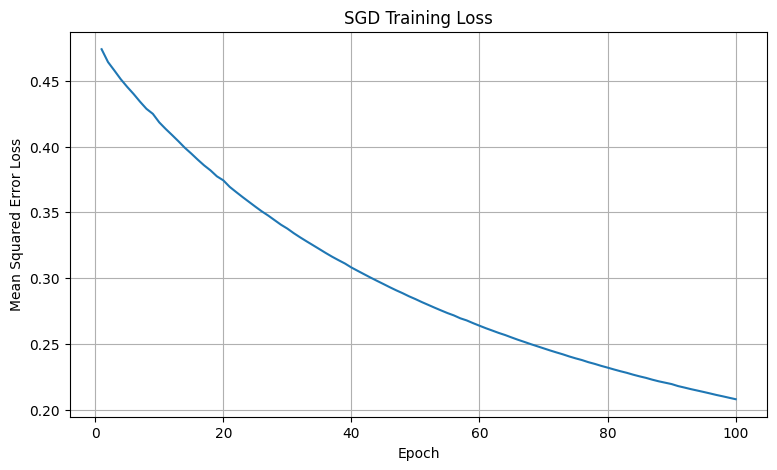

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, epochs + 1), loss_history_sgd)
plt.title("SGD Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.grid(True)
plt.show()


## 11. Evaluate the Model

We use the trained weights to predict profit for the test set. Predictions are converted back to the original `Profit` scale, then evaluated using MSE, RMSE, MAE, and R².

In [11]:
y_pred_scaled_sgd = X_test_norm @ W_sgd
y_pred_sgd = y_pred_scaled_sgd * y_std + y_mean

mse_sgd = mean_squared_error(y_test, y_pred_sgd)
rmse_sgd = np.sqrt(mse_sgd)
mae_sgd = mean_absolute_error(y_test, y_pred_sgd)
r2_sgd = r2_score(y_test, y_pred_sgd)

print("Stochastic Gradient Descent (SGD) Results")
print("------------------------------------------")
print("MSE:", mse_sgd)
print("RMSE:", rmse_sgd)
print("MAE:", mae_sgd)
print("R2 Score:", r2_sgd)


Stochastic Gradient Descent (SGD) Results
------------------------------------------
MSE: 37821.93812108382
RMSE: 194.47863152820625
MAE: 51.8410748738194
R2 Score: 0.21992698738912697


## 12. Actual vs. Predicted Profit

The scatter plot compares actual profit values with the model's predictions. Points closer to the diagonal reference line represent more accurate predictions.

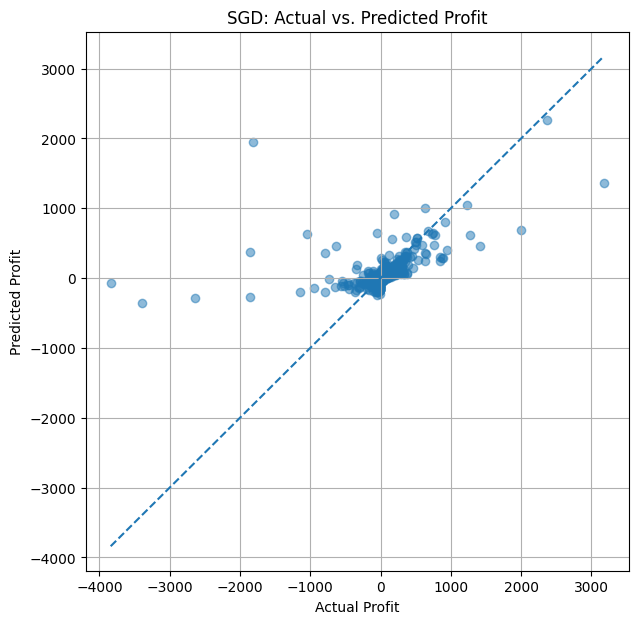

In [12]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_sgd, alpha=0.5)

min_value = min(y_test.min(), y_pred_sgd.min())
max_value = max(y_test.max(), y_pred_sgd.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.title("SGD: Actual vs. Predicted Profit")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.grid(True)
plt.show()


## 13. Results Summary

The following cell displays the final evaluation metrics in a compact table. Keep these results for the final comparison between the five optimization algorithms.

**Note:** SGD is stochastic, so its updates are noisier than full-batch Gradient Descent. Its performance depends on the learning rate, number of epochs, and random order of examples. Compare the test metrics rather than relying on the training loss alone.

In [13]:
sgd_results = pd.DataFrame({
    "Optimizer": ["SGD"],
    "Final Training Loss": [loss_history_sgd[-1]],
    "MSE": [mse_sgd],
    "RMSE": [rmse_sgd],
    "MAE": [mae_sgd],
    "R2 Score": [r2_sgd]
})

display(sgd_results)


,Optimizer,Final Training Loss,MSE,RMSE,MAE,R2 Score
0,SGD,0.207821,37821.938121,194.478632,51.841075,0.219927


## 14. Conclusion

In this notebook, Stochastic Gradient Descent was implemented manually using NumPy for a degree-2 Polynomial Regression model that predicts retail store profit.

Unlike batch Gradient Descent, SGD updates the weights after processing each individual training example. The training-loss curve and test metrics provide a way to assess how well it learned from the dataset.

The final metrics will be compared with the other optimizers in the project. A higher R² and lower RMSE/MAE generally indicate better predictive performance on the test set.